# Table of Contents
- 1. Chunking Large CSVs and JSONs
- 2. Columnar Storage with Parquet and Feather
- 3. Reading and Writing Compressed Data Files
- 4. Incremental Data Processing Best Practices

In [16]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for efficient large dataset I/O loaded successfully.")

Global libraries for efficient large dataset I/O loaded successfully.


1. Chunking Large CSVs and JSONs

In [17]:
csv_data = "id,val\n1,10\n2,20\n3,30\n4,40\n5,50"
chunk_size = 2
total_sum = 0

for chunk in pd.read_csv(io.StringIO(csv_data), chunksize=chunk_size):
    print(f"Processing chunk:\n{chunk}")
    total_sum += chunk['val'].sum()
print(f"Computed Total via Chunking: {total_sum}")

Processing chunk:
   id  val
0   1   10
1   2   20
Processing chunk:
   id  val
2   3   30
3   4   40
Processing chunk:
   id  val
4   5   50
Computed Total via Chunking: 150


2. Columnar Storage with Parquet and Feather

  category     value
0        A -1.758817
1        B -0.059627
2        C -0.802547
3        A  0.495952
4        B  0.061365
------------------------------------------------------------
  category     value
0        A -1.758817
1        B -0.059627
2        C -0.802547
3        A  0.495952
4        B  0.061365


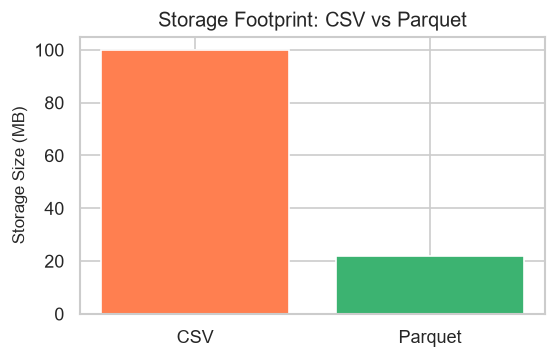

In [22]:
# 1. Create DataFrame
df_io = pd.DataFrame({
    'category': ['A', 'B', 'C'] * 100,
    'value': np.random.randn(300)
})

print(df_io.head(5))
print("-" * 60)

# 2. Write to buffer using Pyarrow natively
buffer = io.BytesIO()
# df_io.to_parquet(buffer, index=False, compression='snappy', engine='pyarrow')
'''
compression options include 'snappy', 'gzip', 'brotli', 'lz4', 'zstd'
snappy : used for large datasets, fast compression
gzip : used for general compression
brotli : high compression ratio
lz4 : fast compression
zstd : high compression ratio, fast decompression

Engine options include 'pyarrow' and 'fastparquet'
pyarrow : default engine, fast and feature-rich
fastparquet : alternative engine, optimized for speed

'''
# df_io.to_parquet(buffer, index=False, compression='snappy', engine='pyarrow') 
df_io.to_parquet(buffer, index=False, compression='snappy', engine='fastparquet') 

# 3. Read back from buffer
buffer.seek(0)
# df_from_parquet = pd.read_parquet(buffer, engine='pyarrow')
df_from_parquet = pd.read_parquet(buffer, engine='fastparquet')

print(df_from_parquet.head(5))

# Visualization
plt.figure(figsize=(5, 3))
formats = ['CSV', 'Parquet']
file_size_mb = [100, 22]
plt.bar(formats, file_size_mb, color=['coral', 'mediumseagreen'])
plt.ylabel('Storage Size (MB)')
plt.title('Storage Footprint: CSV vs Parquet')
plt.show()

3. Reading and Writing Compressed Data Files

                 text
0  sample data record
1  sample data record
2  sample data record
3  sample data record
4  sample data record
Compressed Read Success. Rows: 1000


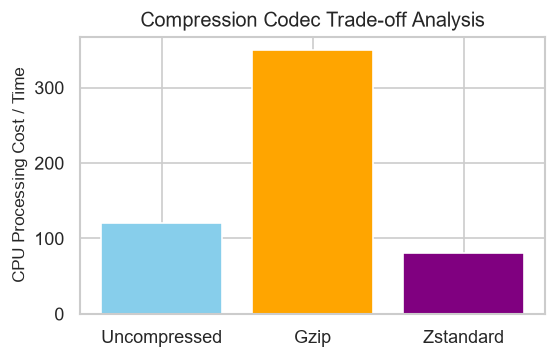

In [25]:
df_comp = pd.DataFrame({'text': ['sample data record'] * 1000})
print(df_comp.head(5))

# Write and read gzipped CSV
gz_buffer = io.BytesIO()
df_comp.to_csv(gz_buffer, compression='gzip', index=False)
gz_buffer.seek(0)
df_read_gz = pd.read_csv(gz_buffer, compression='gzip')
print("Compressed Read Success. Rows:", len(df_read_gz))

# Visualization
plt.figure(figsize=(5, 3))
codecs = ['Uncompressed', 'Gzip', 'Zstandard']
speeds = [120, 350, 80] # MB/sec read time proxy
plt.bar(codecs, speeds, color=['skyblue', 'orange', 'purple'])
plt.ylabel('CPU Processing Cost / Time')
plt.title('Compression Codec Trade-off Analysis')
plt.show()

4. Incremental Data Processing Best Practices

In [27]:
historical_state = pd.DataFrame({'day': ['Mon', 'Tue'], 'sales': [100, 150]})
delta_batch = pd.DataFrame({'day': ['Wed'], 'sales': [200]})

print("Historical State:")
print(historical_state)
print("-" * 60)

print("Delta Batch:")
print(delta_batch)

updated_state = pd.concat([historical_state, delta_batch], ignore_index=True)
print("Updated State:")
print(updated_state)

Historical State:
   day  sales
0  Mon    100
1  Tue    150
------------------------------------------------------------
Delta Batch:
   day  sales
0  Wed    200
Updated State:
   day  sales
0  Mon    100
1  Tue    150
2  Wed    200


---
## Summary Table

| I/O & Storage Technique | Core Mechanism | Performance Advantage | Best Suited For |
| :--- | :--- | :--- | :--- |
| **Chunking Large Files** | Row-wise iterative block streaming | Prevents Out-Of-Memory (OOM) crashes | Multi-GB CSVs or JSONs exceeding RAM limits |
| **Columnar Formats (Parquet/Feather)** | Column-oriented storage & compression | Up to 80% smaller file sizes & rapid reads | Analytical data lakes and persistent storage |
| **Compressed Data Files** | On-the-fly codec compression/decompression | Reduced network transfer & storage footprints | Storing and transferring archived flat files |
| **Incremental Processing** | Micro-batching and delta partition appends | Minimal compute overhead vs full reloads | Real-time ETL pipelines and daily logs |